In [ ]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from datasets import load_dataset
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.14.1+cu130
Device: cuda


In [ ]:
FAST_MODE = True

TRAIN_SIZE = 10_000 if FAST_MODE else 45_000
VAL_SIZE = 2_000 if FAST_MODE else 5_000
TEST_SIZE = 2_000 if FAST_MODE else 10_000
BATCH_SIZE = 128

# Download once from the Hugging Face Hub and reuse its local cache.
cifar = load_dataset("uoft-cs/cifar10")
class_names = cifar["train"].features["label"].names

# Keep class proportions stable in the train-validation split.
split = cifar["train"].train_test_split(
    test_size=5_000,
    seed=SEED,
    stratify_by_column="label",
)

train_source = split["train"].shuffle(seed=SEED).select(range(TRAIN_SIZE))
validation_source = split["test"].shuffle(seed=SEED).select(range(VAL_SIZE))
test_source = cifar["test"].shuffle(seed=SEED).select(range(TEST_SIZE))

print("Train examples:", len(train_source))
print("Validation examples:", len(validation_source))
print("Test examples:", len(test_source))
print("Classes:", class_names)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Train examples: 10000
Validation examples: 2000
Test examples: 2000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
class HFCIFAR10(Dataset):
    # Adapt a Hugging Face image split to PyTorch's Dataset interface.

    def __init__(self, source, transform=None):
        self.source = source
        self.transform = transform

    def __len__(self):
        return len(self.source)

    def __getitem__(self, index):
        sample = self.source[index]
        image = sample["img"].convert("RGB")
        label = sample["label"]

        if self.transform is not None:
            image = self.transform(image)

        return image, label

In [ ]:
def make_loaders(train_transform, eval_transform):
    training_data = HFCIFAR10(train_source, train_transform)
    validation_data = HFCIFAR10(validation_source, eval_transform)
    test_data = HFCIFAR10(test_source, eval_transform)

    options = {
        "batch_size": BATCH_SIZE,
        "num_workers": 2,
        "pin_memory": torch.cuda.is_available(),
    }

    return {
        "train": DataLoader(
            training_data,
            shuffle=True,
            **options,
        ),
        "validation": DataLoader(
            validation_data,
            shuffle=False,
            **options,
        ),
        "test": DataLoader(
            test_data,
            shuffle=False,
            **options,
        ),
    }

In [ ]:
baseline_transform = transforms.ToTensor()

baseline_loaders = make_loaders(
    train_transform=baseline_transform,
    eval_transform=baseline_transform,
)

images, labels = next(iter(baseline_loaders["train"]))

print("Image batch:", images.shape)
print("Label batch:", labels.shape)
print("Pixel range:", images.min().item(), images.max().item())

Image batch: torch.Size([128, 3, 32, 32])
Label batch: torch.Size([128])
Pixel range: 0.0 1.0


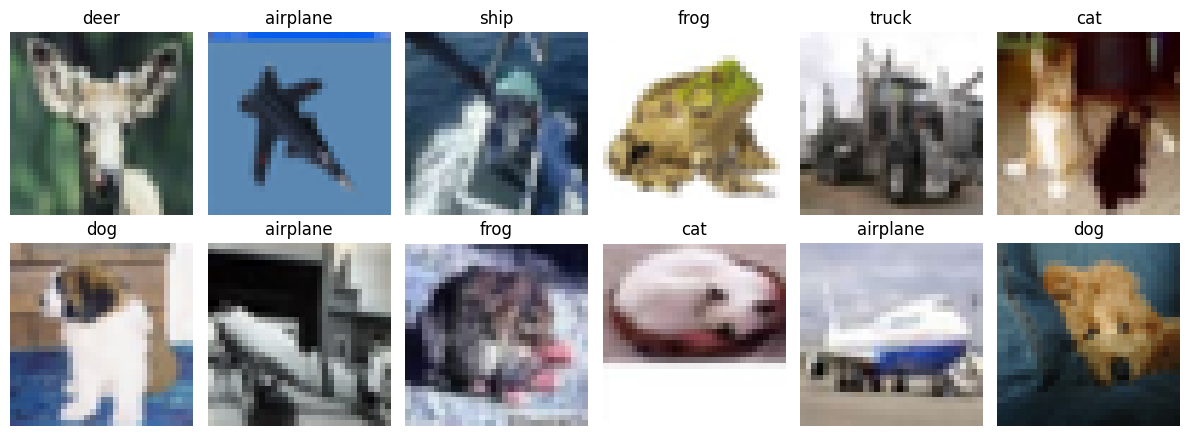

In [ ]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))

for ax, image, label in zip(
    axes.ravel(),
    images[:12],
    labels[:12],
):
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[label.item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, use_batch_norm=False, dropout=0.0):
        super().__init__()

        first_block = [nn.Conv2d(3, 32, kernel_size=3, padding=1)]
        if use_batch_norm:
            first_block.append(nn.BatchNorm2d(32))
        first_block += [nn.ReLU(), nn.MaxPool2d(2)]

        second_block = [nn.Conv2d(32, 64, kernel_size=3, padding=1)]
        if use_batch_norm:
            second_block.append(nn.BatchNorm2d(64))
        second_block += [nn.ReLU(), nn.MaxPool2d(2)]

        self.features = nn.Sequential(
            *first_block,
            *second_block,
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

baseline_model = SmallCNN(use_batch_norm=False).to(device)
print(baseline_model)
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in baseline_model.parameters()):,}",
)

SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 545,098


In [ ]:
list(baseline_model.features[1].parameters())#[0].numel()

[]

input - 128 x 3 x 32 x 32
output after applying nn.Conv2d(3, 32, kernel_size=3, padding=1) - 128 x 32 x 32 x 32

output after applying nn.Conv2d(32, 64, kernel_size=3, padding=1) - 128 x 64 x 16 x 16


In [ ]:
loss_function = nn.CrossEntropyLoss()

baseline_model.eval()
with torch.no_grad():
    initial_logits = baseline_model(images.to(device))
    initial_loss = loss_function(
        initial_logits,
        labels.to(device),
    ).item()

print(f"Observed initial loss: {initial_loss:.3f}")
# print(f"Uniform-prediction reference: {math.log(10):.3f}")

Observed initial loss: 2.303


In [ ]:
dropout = nn.Dropout(p=0.5)
activations = torch.ones(12)
print(activations)

dropout.train()
print("Training pass 1:", dropout(activations))
print("Training pass 2:", dropout(activations))

# dropout.eval()
# print("Evaluation:    ", dropout(activations))

tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])
Training pass 1: tensor([2., 2., 0., 0., 0., 0., 2., 2., 2., 2., 2., 0.])
Training pass 2: tensor([0., 0., 0., 0., 0., 2., 0., 2., 2., 2., 2., 2.])


In [ ]:
def run_epoch(model, data_loader, loss_function, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for batch_images, batch_labels in data_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(batch_images)
            loss = loss_function(logits, batch_labels)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = batch_labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (
            logits.argmax(dim=1) == batch_labels
        ).sum().item()
        total_examples += batch_size

    return {
        "loss": total_loss / total_examples,
        "accuracy": total_correct / total_examples,
    }

In [ ]:
def fit_model(
    model,
    loaders,
    epochs,
    learning_rate,
    checkpoint_path,
    patience=None,
    use_scheduler=False,
):
    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
    )
    scheduler = None
    if use_scheduler:
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=epochs,
            eta_min=learning_rate * 0.50,
        )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "validation_loss": [],
        "validation_accuracy": [],
        "learning_rate": [],
    }

    best_validation_loss = float("inf")
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        current_lr = optimizer.param_groups[0]["lr"]

        train_metrics = run_epoch(
            model,
            loaders["train"],
            loss_function,
            optimizer,
        )
        validation_metrics = run_epoch(
            model,
            loaders["validation"],
            loss_function,
        )

        history["train_loss"].append(train_metrics["loss"])
        history["train_accuracy"].append(train_metrics["accuracy"])
        history["validation_loss"].append(validation_metrics["loss"])
        history["validation_accuracy"].append(
            validation_metrics["accuracy"]
        )
        history["learning_rate"].append(current_lr)

        if scheduler is not None:
            scheduler.step()

        improved = validation_metrics["loss"] < best_validation_loss

        if improved:
            best_validation_loss = validation_metrics["loss"]
            epochs_without_improvement = 0

            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": (
                        scheduler.state_dict()
                        if scheduler is not None
                        else None
                    ),
                    "validation_loss": best_validation_loss,
                },
                checkpoint_path,
            )
        else:
            epochs_without_improvement += 1

        print(
            f"Epoch {epoch:02d} | "
            f"train loss {train_metrics['loss']:.3f} | "
            f"val loss {validation_metrics['loss']:.3f} | "
            f"val acc {validation_metrics['accuracy']:.3f} | "
            f"lr {current_lr:.5f}"
        )

        if (
            patience is not None
            and epochs_without_improvement >= patience
        ):
            print("Early stopping.")
            break

    return history

In [ ]:
BASELINE_EPOCHS = 15 if FAST_MODE else 12

baseline_model = SmallCNN().to(device)

baseline_history = fit_model(
    model=baseline_model,
    loaders=baseline_loaders,
    epochs=BASELINE_EPOCHS,
    learning_rate=1e-3,
    checkpoint_path="baseline_best.pt",
)

Epoch 01 | train loss 1.955 | val loss 1.734 | val acc 0.374 | lr 0.00100
Epoch 02 | train loss 1.577 | val loss 1.577 | val acc 0.447 | lr 0.00100
Epoch 03 | train loss 1.420 | val loss 1.460 | val acc 0.467 | lr 0.00100
Epoch 04 | train loss 1.325 | val loss 1.421 | val acc 0.493 | lr 0.00100
Epoch 05 | train loss 1.256 | val loss 1.345 | val acc 0.504 | lr 0.00100
Epoch 06 | train loss 1.216 | val loss 1.278 | val acc 0.543 | lr 0.00100
Epoch 07 | train loss 1.135 | val loss 1.259 | val acc 0.554 | lr 0.00100
Epoch 08 | train loss 1.079 | val loss 1.260 | val acc 0.550 | lr 0.00100
Epoch 09 | train loss 1.040 | val loss 1.295 | val acc 0.554 | lr 0.00100
Epoch 10 | train loss 1.006 | val loss 1.233 | val acc 0.566 | lr 0.00100
Epoch 11 | train loss 0.942 | val loss 1.275 | val acc 0.555 | lr 0.00100
Epoch 12 | train loss 0.890 | val loss 1.202 | val acc 0.579 | lr 0.00100
Epoch 13 | train loss 0.856 | val loss 1.160 | val acc 0.599 | lr 0.00100
Epoch 14 | train loss 0.794 | val loss

In [ ]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(degrees=5),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

improved_loaders = make_loaders(
    train_transform=train_transform,
    eval_transform=eval_transform,
)

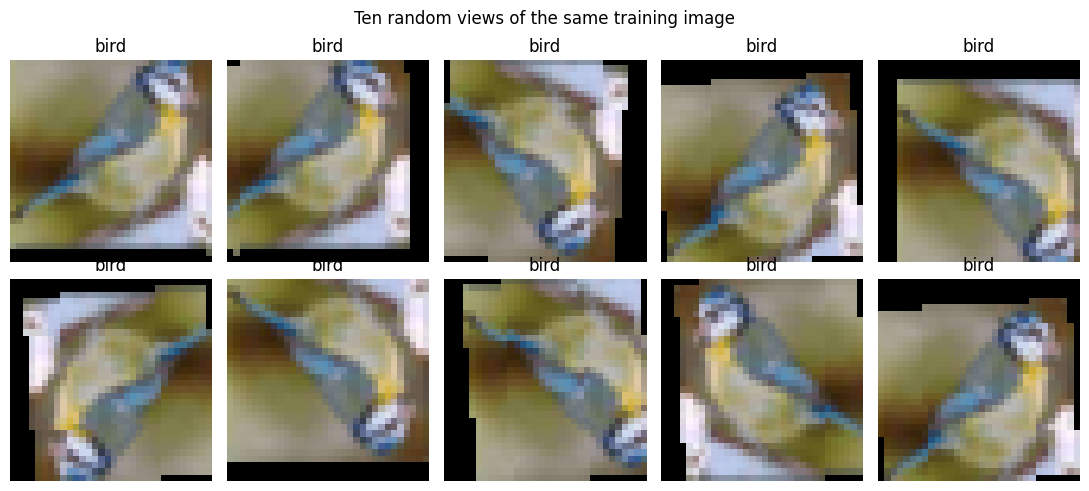

In [ ]:
augmented_dataset = improved_loaders["train"].dataset

fig, axes = plt.subplots(2, 5, figsize=(11, 5))

for ax in axes.ravel():
    image, label = augmented_dataset[0]

    # Undo normalization only for display.
    mean = torch.tensor(CIFAR_MEAN)[:, None, None]
    std = torch.tensor(CIFAR_STD)[:, None, None]
    display_image = (image * std + mean).clamp(0, 1)

    ax.imshow(display_image.permute(1, 2, 0))
    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle("Ten random views of the same training image")
plt.tight_layout()
plt.show()

In [ ]:
IMPROVED_EPOCHS = 15 if FAST_MODE else 25

improved_model = SmallCNN(
    use_batch_norm=True,
    dropout=0.10,
).to(device)

improved_history = fit_model(
    model=improved_model,
    loaders=improved_loaders,
    epochs=IMPROVED_EPOCHS,
    learning_rate=1e-3,
    checkpoint_path="improved_best.pt",
    patience=3,
    use_scheduler=True,
)

Epoch 01 | train loss 2.034 | val loss 1.869 | val acc 0.282 | lr 0.00100
Epoch 02 | train loss 1.762 | val loss 1.654 | val acc 0.382 | lr 0.00099
Epoch 03 | train loss 1.654 | val loss 1.573 | val acc 0.410 | lr 0.00098
Epoch 04 | train loss 1.591 | val loss 1.517 | val acc 0.434 | lr 0.00095
Epoch 05 | train loss 1.549 | val loss 1.512 | val acc 0.442 | lr 0.00092
Epoch 06 | train loss 1.509 | val loss 1.481 | val acc 0.451 | lr 0.00088
Epoch 07 | train loss 1.480 | val loss 1.493 | val acc 0.449 | lr 0.00083
Epoch 08 | train loss 1.449 | val loss 1.361 | val acc 0.497 | lr 0.00078
Epoch 09 | train loss 1.430 | val loss 1.372 | val acc 0.488 | lr 0.00072
Epoch 10 | train loss 1.421 | val loss 1.323 | val acc 0.518 | lr 0.00067
Epoch 11 | train loss 1.396 | val loss 1.352 | val acc 0.507 | lr 0.00063
Epoch 12 | train loss 1.359 | val loss 1.292 | val acc 0.519 | lr 0.00058
Epoch 13 | train loss 1.366 | val loss 1.273 | val acc 0.531 | lr 0.00055
Epoch 14 | train loss 1.369 | val loss

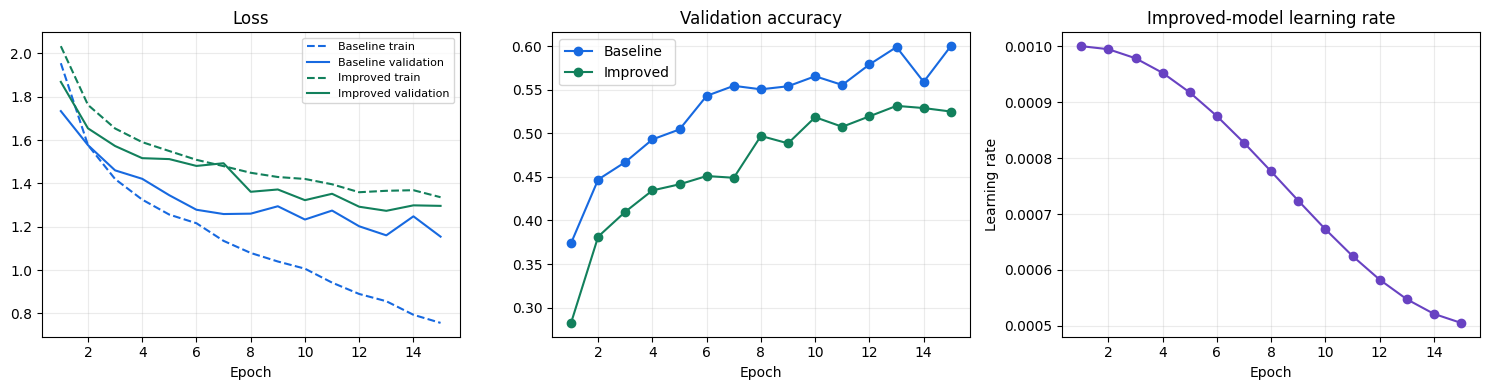

In [ ]:
def plot_comparison(baseline, improved):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for history, name, color in [
        (baseline, "Baseline", "#1769e0"),
        (improved, "Improved", "#12805c"),
    ]:
        epochs = np.arange(1, len(history["train_loss"]) + 1)

        axes[0].plot(
            epochs,
            history["train_loss"],
            color=color,
            linestyle="--",
            label=f"{name} train",
        )
        axes[0].plot(
            epochs,
            history["validation_loss"],
            color=color,
            label=f"{name} validation",
        )
        axes[1].plot(
            epochs,
            history["validation_accuracy"],
            color=color,
            marker="o",
            label=name,
        )

    improved_epochs = np.arange(
        1,
        len(improved["learning_rate"]) + 1,
    )
    axes[2].plot(
        improved_epochs,
        improved["learning_rate"],
        color="#6842c2",
        marker="o",
    )

    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.25)

    axes[1].set_title("Validation accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    axes[2].set_title("Improved-model learning rate")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("Learning rate")
    axes[2].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()


plot_comparison(baseline_history, improved_history)